### Ned – Lösung Schritt für Schritt

*30. Bundeswettbewerb Informatik (2011/2012), 2. Runde, Aufgabe 1*

Im Winter ist Konrad für das Streuen der Straßen in seiner kleinen Stadt zuständig. Wenn die Nacht kalt war und Glatteis droht,
fährt er mit seinem Streufahrzeug, das er liebevoll „Ned“ nennt¹, alle Straßen der Stadt ab und streut Sand.

Leider hat sein Streufahrzeug nur eine begrenzte Ladekapazität. Der Sand reicht gerade zum Streuen von 12 km Straße. Wenn der
Sand verstreut ist, fährt Konrad zum Depot zurück und lädt weiteren Sand. Sind alle Straßen gestreut, hat Konrad frei – bis zum
nächsten Morgen. Glücklichweise bilden die Straßen in seiner Stadt ein sehr übersichtliches Netz. Alle Straßen verlaufen entlang
eines Rasters mit einer Rasterweite von 1 km. Abzweigungen und Kreuzungen liegen nur an den Rasterpunkten.

Beim Streuen erreicht Konrad die gesamte Straßenbreite, jeder Straßenabschnitt muss also nur einmal gestreut werden. Konrad kann
nur an Rasterpunkten wenden. Er darf auch dann zum Depot zurückkehren und bei Bedarf neuen Sand laden, wenn er noch Sand auf
seinem Fahrzeug hat.

#### Aufgabe

1. Schreibe ein Programm, das ermittelt, wie Konrad fahren kann, um alle Straßen zu streuen und zum Depot zurückzukehren.
2. Erweitere dein Programm so, dass die Gesamtfahrstrecke möglichst gering wird.
3. Demonstriere beide Programme an den unten abgebildeten Staßennetzen und an weiteren Beispielen.
4. Untersuche, welchen Einfluss die Ladekapazität auf die Schwierigkeiten hat, eine möglichst geringe Gesamtfahrstrecke zu
   ermitteln.

¹ Konrad, der alte Lateiner, hat nun mal den Leitsatz „Nix est dissolvenda“.

*(Bilder im Aufgabenblatt: zwei Straßennetze auf einem Raster von 6 × 6 km, das Depot jeweils in der linken unteren Ecke.
Links: der Rand des Quadrats, eine senkrechte Straße durch die Mitte und von deren Mitte eine Straße zum rechten Rand.
Rechts: der Rand des Quadrats, darin ein zweites Quadrat mit 4 km Seitenlänge, das mit jeder Seite des äußeren Quadrats durch ein
1 km langes Straßenstück verbunden ist.)*

#### Beispieldaten

Laut BWINF-Archiv gibt es zu dieser Aufgabe keine Beispieldaten. Wir haben die Straßennetze deshalb selbst in Dateien geschrieben.
Das Format ist unsere Wahl: In der ersten Zeile steht die Ladekapazität T (in km), in der zweiten das Depot, danach in jeder Zeile
eine gerade Straße mit Anfangs- und Endpunkt (x1 y1 x2 y2). Der Ursprung (0|0) liegt links unten, x zeigt nach rechts, y nach
oben. Alles hinter `#` ist ein Kommentar.

In `beispieldaten/`:
- `beispiel1.txt` und `beispiel2.txt`: die beiden Netze aus dem Aufgabenblatt (aus den Bildern abgelesen) mit T = 12. Sie haben
  33 bzw. 44 Abschnitte von 1 km, so wie es auch die Lösungshinweise angeben.
- `hinweise_abb1.txt`: das kleine Netz aus Abbildung 1a der Lösungshinweise (10 Abschnitte, T = 4).
- `hinweise_abb3.txt`: das Netz aus Abbildung 3 der Lösungshinweise (eine senkrechte Straße von 2 km vom Depot zu einer waagerechten
  Straße von 4 km, T = 3). Laut Hinweisen ist die kürzeste Gesamtstrecke 16 km.

In `eigene_testdaten/`: `sackgasse.txt` (eine 7 km lange Sackgasse, T = 3), `gitter.txt` (ein volles Gitter mit 4 × 4
Kreuzungen, T = 8) und `beispiel1_depot_mitte.txt` (Beispiel 1 mit dem Depot an der Kreuzung in der Mitte).

## Was dir bei dieser Aufgabe hilft

**Algorithmische Kenntnisse**
- **Graphen:** Die Rasterpunkte an den Straßen sind die Knoten, die Straßenabschnitte von 1 km die Kanten.
- **Breitensuche:** Weil jeder Abschnitt 1 km lang ist, liefert sie die kürzesten Wege zwischen allen Rasterpunkten. Wir brauchen
  sie auch für die exakte Suche bei kleinen Netzen, dort über „Zustände“ statt über Rasterpunkte.
- **Dynamische Programmierung:** Ist die Reihenfolge der Abschnitte festgelegt, berechnet eine Tabelle schnell, wann Konrad am
  besten zum Depot zurückfährt und in welcher Richtung er jeden Abschnitt streut. Das ist der zentrale Trick der Lösungshinweise.
- **Lokale Suche (Bergsteigen):** Eine Reihenfolge immer wieder ein wenig ändern und die Änderung behalten, wenn der Plan kürzer
  wird. Mit kleinen zufälligen **Störungen** kommen wir aus Sackgassen heraus („iterierte lokale Suche“).
- **Briefträgerproblem (Chinese Postman Problem):** Wenn der Sand für alles reicht, sucht man die kürzeste Rundfahrt über alle
  Straßen. Dafür braucht man Eulertouren und eine Paarung der Kreuzungen mit ungerader Anzahl von Straßen.

**Nützliche Funktionen und Bibliotheken**
- `collections.deque` als Warteschlange für die Breitensuche (`append`, `popleft`).
- Dictionarys mit Tupeln als Schlüssel, z. B. `abstand[(0, 0)][(3, 6)]`.
- `frozenset`: eine unveränderliche Menge, die man (anders als `set`) als Teil eines Schlüssels im Dictionary verwenden kann.
- Listen-Slicing: `folge[i:j][::-1]` dreht ein Stück einer Liste um.
- `random.Random(zahl)`: ein Zufallsgenerator mit festem Startwert, damit die Ausgaben bei jedem Lauf gleich sind.
- `matplotlib` zum Zeichnen der Rundfahrten.

## Die Idee in Worten

**Das Netz.** Wir zerlegen jede Straße in Abschnitte von 1 km zwischen zwei benachbarten Rasterpunkten. Ein **Streuplan** besteht
aus Rundfahrten. Jede Rundfahrt beginnt am Depot mit vollem Wagen, streut höchstens T Abschnitte und endet am Depot. Zwischen den
Abschnitten, die er streut, fährt Konrad immer auf einem kürzesten Weg; dabei darf er auch über Abschnitte fahren, ohne zu streuen.

**Teil 1 (irgendein Plan).** Wir nehmen die Abschnitte in irgendeiner Reihenfolge und fahren nach jeweils T Abschnitten zum Depot.
Etwas besser: Konrad fährt immer zum nächsten Abschnitt, der noch nicht gestreut ist (gierig).

**Teil 2 (möglichst kurz).** Die Lösungshinweise beschreiben einen schönen Trick: Wir legen nur die **Reihenfolge** fest, in der
die Abschnitte gestreut werden. Wann Konrad dabei zum Depot zurückfährt und in welcher **Richtung** er jeden Abschnitt streut,
berechnet eine dynamische Programmierung optimal. Dann suchen wir nur noch eine gute Reihenfolge: mit lokaler Suche, die ein Stück
der Reihenfolge umdreht oder einen Abschnitt an eine andere Stelle verschiebt.

**Prüfen.** Für kleine Netze finden wir mit einer Breitensuche über alle Zustände (welche Abschnitte gestreut sind, wo Konrad steht,
wie viel Sand er hat) den garantiert kürzesten Plan und vergleichen.

**Teil 4.** Bei T = 1 ist alles einfach: Jeder Abschnitt braucht eine eigene Fahrt. Reicht der Sand für alles, ist es das
Briefträgerproblem, für das es ein schnelles Verfahren gibt. Dazwischen ist das Problem NP-schwer (Capacitated Arc Routing Problem).

## Schritt 1: Das Straßennetz einlesen

`lies_netz` zerlegt jede Straße in Abschnitte von 1 km. Ein Abschnitt ist ein Paar von Rasterpunkten, der kleinere Punkt zuerst,
damit jeder Abschnitt nur einmal vorkommt (auch wenn sich zwei Straßen überlappen). `baue_netz` merkt sich zu jedem Punkt die
Nachbarn und berechnet mit einer Breitensuche von jedem Punkt aus die Abstände zu allen anderen Punkten.

In [ ]:
from collections import deque
import random
import matplotlib.pyplot as plt


def breitensuche(nachbarn, start):
    """Abstände (in km) von start zu allen erreichbaren Punkten."""
    abstand = {start: 0}
    schlange = deque([start])
    while schlange:
        p = schlange.popleft()
        for q in nachbarn[p]:
            if q not in abstand:
                abstand[q] = abstand[p] + 1
                schlange.append(q)
    return abstand


def baue_netz(T, depot, abschnitte):
    nachbarn = {}
    for a, b in abschnitte:
        nachbarn.setdefault(a, []).append(b)
        nachbarn.setdefault(b, []).append(a)
    for p in nachbarn:
        nachbarn[p].sort()
    if depot not in nachbarn:
        raise ValueError('Das Depot liegt an keiner Straße.')
    abstand = {}
    for p in nachbarn:
        abstand[p] = breitensuche(nachbarn, p)
    if len(abstand[depot]) != len(nachbarn):
        raise ValueError('Das Straßennetz hängt nicht zusammen.')
    return {'T': T, 'depot': depot, 'abschnitte': abschnitte, 'nachbarn': nachbarn, 'abstand': abstand}


def lies_netz(dateiname):
    zeilen = []
    with open(dateiname, encoding='utf-8') as datei:
        for zeile in datei:
            zeile = zeile.split('#')[0].strip()          # Kommentar abschneiden
            if zeile != '':
                zeilen.append([int(wort) for wort in zeile.split()])
    T = zeilen[0][0]
    depot = (zeilen[1][0], zeilen[1][1])
    abschnitte = set()
    for x1, y1, x2, y2 in zeilen[2:]:
        if x1 != x2 and y1 != y2:
            raise ValueError(f'Straße nicht waagerecht oder senkrecht: {x1} {y1} {x2} {y2}')
        laenge = abs(x2 - x1) + abs(y2 - y1)
        dx = (x2 - x1) // laenge                          # -1, 0 oder 1
        dy = (y2 - y1) // laenge
        for i in range(laenge):
            a = (x1 + i * dx, y1 + i * dy)
            b = (a[0] + dx, a[1] + dy)
            abschnitte.add((min(a, b), max(a, b)))
    return baue_netz(T, depot, sorted(abschnitte))


DATEIEN = ['beispieldaten/beispiel1.txt', 'beispieldaten/beispiel2.txt', 'beispieldaten/hinweise_abb1.txt',
           'beispieldaten/hinweise_abb3.txt', 'eigene_testdaten/sackgasse.txt', 'eigene_testdaten/gitter.txt',
           'eigene_testdaten/beispiel1_depot_mitte.txt']
NETZ = {}
for dateiname in DATEIEN:
    name = dateiname.split('/')[1][:-4]
    NETZ[name] = lies_netz(dateiname)
    netz = NETZ[name]
    print(f"{name:22} T = {netz['T']:2}   Depot {netz['depot']}   {len(netz['abschnitte']):2} Abschnitte, "
          f"{len(netz['nachbarn']):2} Punkte, am weitesten vom Depot: {max(netz['abstand'][netz['depot']].values())} km")

beispiel1              T = 12   Depot (0, 0)   33 Abschnitte, 31 Punkte, am weitesten vom Depot: 12 km
beispiel2              T = 12   Depot (0, 0)   44 Abschnitte, 40 Punkte, am weitesten vom Depot: 12 km
hinweise_abb1          T =  4   Depot (1, 1)   10 Abschnitte,  9 Punkte, am weitesten vom Depot: 4 km
hinweise_abb3          T =  3   Depot (2, 2)    6 Abschnitte,  7 Punkte, am weitesten vom Depot: 4 km
sackgasse              T =  3   Depot (0, 0)    7 Abschnitte,  8 Punkte, am weitesten vom Depot: 7 km
gitter                 T =  8   Depot (0, 0)   24 Abschnitte, 16 Punkte, am weitesten vom Depot: 6 km
beispiel1_depot_mitte  T = 12   Depot (3, 3)   33 Abschnitte, 31 Punkte, am weitesten vom Depot: 9 km


Beide Netze aus dem Aufgabenblatt haben 33 bzw. 44 Abschnitte, wie in den Lösungshinweisen (dort m = 33 und m = 44).

## Schritt 2: Streupläne darstellen und prüfen

Ein **Plan** ist eine Liste von Rundfahrten. Eine Rundfahrt ist die Liste der Abschnitte, die sie streut, in der Reihenfolge und
Richtung des Streuens, z. B. `[((0, 0), (0, 1)), ((0, 1), (0, 2))]`. Die Wege dazwischen ergänzt `fahrten`: Es fährt vom Depot
auf einem kürzesten Weg zum Anfang des ersten Abschnitts, streut ihn, fährt zum nächsten usw. und am Ende zurück zum Depot.
Das Ergebnis ist für jede Rundfahrt eine Liste von **Schritten** `(von, nach, streut)` über je 1 km.

Einen kürzesten Weg findet `weg` ohne weitere Suche: Von `p` aus gehen wir immer zu einem Nachbarn, der dem Ziel um 1 km näher ist.

`pruefe` rechnet unabhängig davon nach, dass die Schritte wirklich ein gültiger Plan sind: Jeder Schritt führt über eine Straße,
jede Rundfahrt beginnt und endet am Depot und streut höchstens T Abschnitte, und am Ende ist jeder Abschnitt genau einmal
gestreut. Es gibt die Gesamtstrecke in km zurück. Jeden Plan in diesem Notebook prüfen wir damit.

In [ ]:
def weg(netz, p, q):
    """Ein kürzester Weg von p nach q als Liste von Punkten."""
    punkte = [p]
    while p != q:
        for r in netz['nachbarn'][p]:
            if netz['abstand'][r][q] == netz['abstand'][p][q] - 1:
                p = r
                break
        punkte.append(p)
    return punkte


def fahrten(netz, plan):
    """Zu jeder Rundfahrt die Schritte (von, nach, streut), vom Depot bis zurück zum Depot."""
    alle = []
    for rundfahrt in plan:
        schritte = []
        ort = netz['depot']
        for p, q in rundfahrt + [(netz['depot'], None)]:
            punkte = weg(netz, ort, p)                      # leer hinfahren ...
            for i in range(len(punkte) - 1):
                schritte.append((punkte[i], punkte[i + 1], False))
            if q is not None:                               # ... und den Abschnitt streuen
                schritte.append((p, q, True))
                ort = q
        alle.append(schritte)
    return alle


def pruefe(netz, alle_fahrten):
    """Prüft die Fahrten und gibt die Gesamtstrecke in km zurück."""
    gestreut = set()
    km = 0
    for schritte in alle_fahrten:
        ort = netz['depot']
        sand = netz['T']
        for p, q, streut in schritte:
            assert p == ort and q in netz['nachbarn'][p], f'kein Weg von {ort} über {p} nach {q}'
            if streut:
                abschnitt = (min(p, q), max(p, q))
                assert abschnitt not in gestreut, f'{abschnitt} zweimal gestreut'
                assert sand > 0, 'kein Sand mehr'
                gestreut.add(abschnitt)
                sand = sand - 1
            ort = q
            km = km + 1
        assert ort == netz['depot'], 'nicht zum Depot zurückgekehrt'
    assert len(gestreut) == len(netz['abschnitte']), 'nicht alle Abschnitte gestreut'
    return km

Zur Ausgabe fassen wir gerade Stücke zusammen und zeigen nur die Punkte, an denen Konrad abbiegt, wendet oder mit dem Streuen
anfängt oder aufhört: `==>` heißt streuen, `-->` heißt nur fahren. `zeichne` malt jede Rundfahrt in ein eigenes Bild: gestreute
Abschnitte dick und farbig mit einem Pfeil in Fahrtrichtung, Leerfahrten gestrichelt, das Depot als Quadrat.

In [ ]:
def punkt(p):
    return f'({p[0]}|{p[1]})'


def richtung(schritt):
    p, q, streut = schritt
    return (q[0] - p[0], q[1] - p[1], streut)


def zeige(netz, alle_fahrten, nur_kurz=False):
    for nr, schritte in enumerate(alle_fahrten, 1):
        teile = [punkt(schritte[0][0])]
        for i in range(len(schritte)):
            if i == len(schritte) - 1 or richtung(schritte[i]) != richtung(schritte[i + 1]):
                teile.append(('==> ' if schritte[i][2] else '--> ') + punkt(schritte[i][1]))
        gestreut = sum(1 for schritt in schritte if schritt[2])
        print(f'Rundfahrt {nr}: {gestreut:2} km gestreut, {len(schritte):2} km gefahren')
        if not nur_kurz:
            for i in range(0, len(teile), 9):
                print('    ' + ' '.join(teile[i:i + 9]))
    print('Gesamtstrecke:', pruefe(netz, alle_fahrten), 'km')


FARBEN = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple', 'tab:brown', 'tab:pink', 'tab:olive']


def zeichne(netz, alle_fahrten, titel=''):
    anzahl = len(alle_fahrten)
    fig, achsen = plt.subplots(1, anzahl, figsize=(2.6 * anzahl, 2.8), squeeze=False)
    for nr, schritte in enumerate(alle_fahrten):
        ax = achsen[0][nr]
        for a, b in netz['abschnitte']:
            ax.plot([a[0], b[0]], [a[1], b[1]], color='lightgray', linewidth=6, zorder=1)
        farbe = FARBEN[nr % len(FARBEN)]
        for p, q, streut in schritte:
            if streut:
                ax.plot([p[0], q[0]], [p[1], q[1]], color=farbe, linewidth=4, zorder=2)
                ax.annotate('', xy=(0.35 * p[0] + 0.65 * q[0], 0.35 * p[1] + 0.65 * q[1]), xytext=(p[0], p[1]),
                            arrowprops={'arrowstyle': '->', 'color': 'black'}, zorder=3)
            else:
                ax.plot([p[0], q[0]], [p[1], q[1]], color=farbe, linewidth=1.5, linestyle='--', zorder=2)
        ax.plot([netz['depot'][0]], [netz['depot'][1]], 's', color='black', markersize=9, zorder=4)
        gestreut = sum(1 for schritt in schritte if schritt[2])
        ax.set_title(f'{nr + 1}: {gestreut} gestreut, {len(schritte)} km', fontsize=9)
        ax.set_aspect('equal')
        ax.axis('off')
    if titel:
        fig.suptitle(titel)
    plt.show()

## Schritt 3: Teil 1 – irgendein gültiger Plan

Der einfachste Plan: Wir streuen die Abschnitte in der Reihenfolge der Liste `netz['abschnitte']` (sortiert nach Punkten), jeden
vom kleineren zum größeren Punkt, und fahren nach jeweils T Abschnitten zurück zum Depot. Das ist immer gültig, aber Konrad fährt
kreuz und quer durch die Stadt.

In [ ]:
def einfacher_plan(netz):
    T = netz['T']
    plan = []
    for i in range(0, len(netz['abschnitte']), T):
        plan.append(netz['abschnitte'][i:i + T])
    return plan


for name in ['beispiel1', 'beispiel2']:
    print(name)
    zeige(NETZ[name], fahrten(NETZ[name], einfacher_plan(NETZ[name])), nur_kurz=True)
    print()

beispiel1
Rundfahrt 1: 12 km gestreut, 56 km gefahren
Rundfahrt 2: 12 km gestreut, 52 km gefahren
Rundfahrt 3:  9 km gestreut, 40 km gefahren
Gesamtstrecke: 148 km

beispiel2
Rundfahrt 1: 12 km gestreut, 36 km gefahren
Rundfahrt 2: 12 km gestreut, 66 km gefahren
Rundfahrt 3: 12 km gestreut, 68 km gefahren
Rundfahrt 4:  8 km gestreut, 38 km gefahren
Gesamtstrecke: 208 km



Besser ist ein **gieriges** Verfahren, so wie Konrad es wohl ohne Computer machen würde: Er fährt immer zum nächsten Abschnitt,
der noch nicht gestreut ist, und streut ihn in der Richtung, deren Anfang näher liegt. Ist der Sand verbraucht, fährt er zum Depot,
lädt nach und macht vom Depot aus weiter. (Bei gleichem Abstand nimmt er den ersten Abschnitt der sortierten Liste.)

In [ ]:
def gieriger_plan(netz):
    abstand = netz['abstand']
    offen = list(netz['abschnitte'])
    plan = []
    while offen:
        rundfahrt = []
        ort = netz['depot']
        while offen and len(rundfahrt) < netz['T']:
            bester = None
            for a, b in offen:
                for p, q in [(a, b), (b, a)]:
                    if bester is None or abstand[ort][p] < abstand[ort][bester[0]]:
                        bester = (p, q)
            p, q = bester
            rundfahrt.append((p, q))
            offen.remove((min(p, q), max(p, q)))
            ort = q
        plan.append(rundfahrt)
    return plan


for name in ['beispiel1', 'beispiel2']:
    print(name)
    zeige(NETZ[name], fahrten(NETZ[name], gieriger_plan(NETZ[name])))
    print()

beispiel1
Rundfahrt 1: 12 km gestreut, 18 km gefahren
    (0|0) ==> (0|6) ==> (3|6) ==> (3|3) --> (3|0) --> (0|0)
Rundfahrt 2: 12 km gestreut, 18 km gefahren
    (0|0) ==> (3|0) ==> (3|3) ==> (6|3) ==> (6|0) --> (0|0)
Rundfahrt 3:  9 km gestreut, 24 km gefahren
    (0|0) --> (3|0) ==> (6|0) --> (6|3) ==> (6|6) ==> (3|6) --> (0|6) --> (0|0)
Gesamtstrecke: 60 km

beispiel2
Rundfahrt 1: 12 km gestreut, 20 km gefahren
    (0|0) ==> (0|6) ==> (4|6) ==> (4|5) ==> (3|5) --> (1|5) --> (1|4) --> (0|4) --> (0|0)
Rundfahrt 2: 12 km gestreut, 20 km gefahren
    (0|0) ==> (3|0) ==> (3|1) ==> (1|1) ==> (1|4) ==> (0|4) --> (1|4) ==> (1|5) ==> (2|5)
    --> (1|5) --> (1|4) --> (0|4) --> (0|0)
Rundfahrt 3: 12 km gestreut, 20 km gefahren
    (0|0) --> (3|0) ==> (6|0) ==> (6|4) ==> (5|4) ==> (5|1) ==> (4|1) --> (3|1) --> (3|0)
    --> (0|0)
Rundfahrt 4:  8 km gestreut, 30 km gefahren
    (0|0) --> (3|0) --> (3|1) ==> (4|1) --> (5|1) --> (5|4) ==> (5|5) ==> (4|5) --> (3|5)
    ==> (2|5) --> (4|5) --> (4|6

Das ist viel kürzer als der einfache Plan. Bei Beispiel 1 trifft das gierige Verfahren schon die 60 km der Lösungshinweise, bei
Beispiel 2 sind es 90 km statt 80 km. In Rundfahrt 4 sieht man, wo Strecke verschenkt wird: Konrad sammelt einzelne Reststücke
ein, die in den Rundfahrten davor liegen geblieben sind, und fährt dafür weite Wege ohne zu streuen. Das gierige Verfahren leert
den Wagen immer ganz und nimmt einfach den nächsten Abschnitt, ohne an später zu denken.

## Schritt 4: Aus einer Reihenfolge den besten Plan machen

Jetzt kommt der Trick der Lösungshinweise. Wir schreiben die Abschnitte in eine Reihenfolge `folge` (ohne Richtung), z. B. die
Reihenfolge, in der das gierige Verfahren sie streut. Konrad soll sie genau in dieser Reihenfolge streuen. Offen ist dann nur
noch:
1. **Wann fährt er zum Depot zurück?** Jede Rundfahrt streut ein zusammenhängendes Stück `folge[j:i]` mit höchstens T Abschnitten.
2. **In welcher Richtung streut er jeden Abschnitt?**

Beides berechnen wir mit dynamischer Programmierung, also mit einer Tabelle, die wir von vorne nach hinten füllen:

- `beste[i]` ist die kürzeste Gesamtstrecke, mit der Konrad die ersten `i` Abschnitte der Folge streuen kann und wieder im Depot
  steht. Es ist `beste[0] = 0`, gesucht ist `beste[m]`.
- Die letzte Rundfahrt dieser Strecke streut ein Stück `folge[j:i]`. Also ist `beste[i]` das Minimum von
  `beste[j] + rundfahrt(folge[j:i])` über alle `j` mit `i - T <= j < i`.
- Die Länge einer Rundfahrt mit fester Reihenfolge berechnet wieder eine kleine Tabelle, Abschnitt für Abschnitt: `g_ab` ist die
  kürzeste Strecke vom Depot bis zum Ende des aktuellen Abschnitts, wenn er von `a` nach `b` gestreut wurde (Konrad steht in `b`),
  `g_ba` dasselbe für die Gegenrichtung. Für den nächsten Abschnitt `(c, d)` gilt
  `g_cd = min(g_ab + abstand[b][c], g_ba + abstand[a][c]) + 1` und entsprechend `g_dc`. Zum Schluss kommt der Rückweg zum Depot dazu.

Wir lassen die Rundfahrt bei jedem `j` beginnen und verlängern sie Abschnitt für Abschnitt. So bekommen wir die Längen aller
Rundfahrten `folge[j:i]` in einem Durchgang. Für jede Folge sind das höchstens m · T Schritte.

Die Lösungshinweise rechnen mit einer etwas anderen Tabelle `D[i][t]` (dazu noch die Richtung), in der `t` der übrige Sand ist; das
Ergebnis ist dasselbe.

Weil wir die Funktion später sehr oft aufrufen, zählen wir die Aufrufe in `zaehler`, und mit `grenze` können wir die Rechnung
abbrechen, sobald klar ist, dass die Folge nicht kürzer als `grenze` wird: `beste[j]` wird mit wachsendem `j` nie kleiner (wer mehr
streut, fährt nicht weniger). Ist `beste[j]` schon `grenze` oder mehr, kann auch `beste[m]` nicht kleiner werden.

In [ ]:
UNENDLICH = 10 ** 9
zaehler = {'bewertungen': 0}


def aufteilung(netz, folge, grenze=UNENDLICH):
    """beste[i]: kürzeste Strecke für die ersten i Abschnitte der Folge, start[i]: wo die letzte Rundfahrt beginnt."""
    zaehler['bewertungen'] += 1
    T = netz['T']
    abstand = netz['abstand']
    depot = netz['depot']
    m = len(folge)
    beste = [0] + [UNENDLICH] * m
    start = [0] * (m + 1)
    for j in range(m):                       # eine Rundfahrt beginnt mit folge[j]
        if beste[j] >= grenze:
            return UNENDLICH, None           # wird nicht kürzer als grenze
        a, b = folge[j]
        g_ab = abstand[depot][a] + 1          # streut a -> b, steht in b
        g_ba = abstand[depot][b] + 1          # streut b -> a, steht in a
        for i in range(j + 1, min(m, j + T) + 1):
            # Die Rundfahrt streut folge[j:i] und fährt zurück zum Depot.
            gesamt = beste[j] + min(g_ab + abstand[b][depot], g_ba + abstand[a][depot])
            if gesamt < beste[i]:
                beste[i] = gesamt
                start[i] = j
            if i == m:
                break
            c, d = folge[i]                  # die Rundfahrt um folge[i] verlängern
            g_cd = min(g_ab + abstand[b][c], g_ba + abstand[a][c]) + 1
            g_dc = min(g_ab + abstand[b][d], g_ba + abstand[a][d]) + 1
            a, b, g_ab, g_ba = c, d, g_cd, g_dc
    return beste[m], start


def laenge(netz, folge, grenze=UNENDLICH):
    return aufteilung(netz, folge, grenze)[0]

Für den Plan selbst gehen wir mit `start` rückwärts durch die Tabelle: Die letzte Rundfahrt ist `folge[start[m]:m]`, die davor endet
bei `start[m]` usw. Für jede Rundfahrt bestimmt `richtungen` die Richtungen mit derselben kleinen Tabelle wie oben, merkt sich aber
in `vorher`, aus welcher Richtung des vorigen Abschnitts der beste Wert kam, und verfolgt das rückwärts.

In [ ]:
def richtungen(netz, stueck):
    """Beste Richtungen für eine Rundfahrt, die die Abschnitte von stueck in dieser Reihenfolge streut."""
    abstand = netz['abstand']
    depot = netz['depot']
    gerichtet = [[(a, b), (b, a)] for a, b in stueck]       # Richtung 0 und Richtung 1
    kosten = [[abstand[depot][p] + 1 for p, q in gerichtet[0]]]
    vorher = [[None, None]]
    for k in range(1, len(stueck)):
        zeile = []
        wahl = []
        for p, q in gerichtet[k]:
            moeglich = [kosten[k - 1][r] + abstand[gerichtet[k - 1][r][1]][p] + 1 for r in range(2)]
            r = 0 if moeglich[0] <= moeglich[1] else 1
            zeile.append(moeglich[r])
            wahl.append(r)
        kosten.append(zeile)
        vorher.append(wahl)
    ende = [kosten[-1][r] + abstand[gerichtet[-1][r][1]][depot] for r in range(2)]
    r = 0 if ende[0] <= ende[1] else 1
    ergebnis = []
    for k in range(len(stueck) - 1, -1, -1):
        ergebnis.append(gerichtet[k][r])
        r = vorher[k][r]
    ergebnis.reverse()
    return ergebnis


def bester_plan(netz, folge):
    km, start = aufteilung(netz, folge)
    stuecke = []
    i = len(folge)
    while i > 0:
        stuecke.append(folge[start[i]:i])
        i = start[i]
    stuecke.reverse()
    return km, [richtungen(netz, stueck) for stueck in stuecke]


def folge_aus(plan):
    """Die Reihenfolge der Abschnitte eines Plans (ohne Richtung)."""
    return [(min(p, q), max(p, q)) for rundfahrt in plan for p, q in rundfahrt]


print(f"{'Netz':22} {'einfach':>8} {'+ Tabelle':>10} {'gierig':>7} {'+ Tabelle':>10}")
for name, netz in NETZ.items():
    zeile = f'{name:22}'
    for plan in [einfacher_plan(netz), gieriger_plan(netz)]:
        km, neu = bester_plan(netz, folge_aus(plan))
        assert km == pruefe(netz, fahrten(netz, neu))      # die Tabelle rechnet richtig
        zeile += f' {pruefe(netz, fahrten(netz, plan)):7} {km:10}'
    print(zeile)

Netz                    einfach  + Tabelle  gierig  + Tabelle
beispiel1                  148        136      60         60
beispiel2                  208        172      90         90
hinweise_abb1               32         24      24         24
hinweise_abb3               22         22      18         18
sackgasse                   32         24      32         24
gitter                      72         68      38         38
beispiel1_depot_mitte      136        130      48         48


Bei der einfachen Reihenfolge spart die Tabelle viel (148 → 136 km und 208 → 172 km): Konrad streut manche Abschnitte andersherum
und kehrt früher um. Bei der gierigen Reihenfolge ändert sie in den meisten Netzen nichts, weil das gierige Verfahren die Richtung
schon passend wählt. Nur in der Sackgasse spart sie 8 km (32 → 24 km): Dort lohnt es sich, den Wagen nicht immer ganz zu leeren.
Die Prüfung mit `pruefe` (im `assert`) bestätigt jedes Mal die Länge, die die Tabelle ausgerechnet hat.

Zur Probe rechnen wir das Beispiel der Lösungshinweise nach. Dort wird für das kleine Netz aus Abbildung 1a mit T = 4 der Plan
(→ 2)(↓ 5)(← 6)(↑ 4) ⊥ (↑ 8)(← 1)(↓ 3)(↓ 7) ⊥ (← 10)(← 9) ⊥ angegeben (⊥ heißt: zurück zum Depot). Die Nummern sind die Abschnitte
im Bild; bei uns liegt das Depot in (1|1).

In [ ]:
netz = NETZ['hinweise_abb1']
NUMMER = {1: ((1, 3), (2, 3)), 2: ((2, 3), (3, 3)), 3: ((1, 2), (1, 3)), 4: ((2, 2), (2, 3)), 5: ((3, 2), (3, 3)),
          6: ((2, 2), (3, 2)), 7: ((1, 1), (1, 2)), 8: ((2, 1), (2, 2)), 9: ((1, 1), (2, 1)), 10: ((2, 1), (3, 1))}
# Richtungen aus dem Plan: -> rechts, <- links, ^ hoch, v runter
plan_hinweise = [[((2, 3), (3, 3)), ((3, 3), (3, 2)), ((3, 2), (2, 2)), ((2, 2), (2, 3))],
                 [((2, 1), (2, 2)), ((2, 3), (1, 3)), ((1, 3), (1, 2)), ((1, 2), (1, 1))],
                 [((3, 1), (2, 1)), ((2, 1), (1, 1))]]
zeige(netz, fahrten(netz, plan_hinweise))
folge_hinweise = [NUMMER[z] for z in [2, 5, 6, 4, 8, 1, 3, 7, 10, 9]]
print('Beste Aufteilung dieser Reihenfolge:', laenge(netz, folge_hinweise), 'km')

Rundfahrt 1:  4 km gestreut, 10 km gefahren
    (1|1) --> (1|3) --> (2|3) ==> (3|3) ==> (3|2) ==> (2|2) ==> (2|3) --> (1|3) --> (1|1)
Rundfahrt 2:  4 km gestreut,  6 km gefahren
    (1|1) --> (2|1) ==> (2|2) --> (2|3) ==> (1|3) ==> (1|1)
Rundfahrt 3:  2 km gestreut,  4 km gefahren
    (1|1) --> (3|1) ==> (1|1)
Gesamtstrecke: 20 km
Beste Aufteilung dieser Reihenfolge: 20 km


Die Tabelle findet für diese Reihenfolge ebenfalls 20 km. (Der Plan in den Hinweisen soll nur die Darstellung erklären; dass es
mit einer anderen Reihenfolge kürzer geht, sehen wir weiter unten.)

## Schritt 5: Teil 2 – eine gute Reihenfolge suchen

Jetzt müssen wir nur noch eine gute Reihenfolge finden. Wir verändern die Reihenfolge immer wieder ein wenig und behalten eine
Änderung, wenn der Plan kürzer wird (**lokale Suche**, Bergsteigen). Zwei Arten von Änderungen:
- **Umdrehen:** Das Stück `folge[i:j]` wird umgedreht. Das ist die Änderung aus den Lösungshinweisen: Die Nachfolger von zwei
  Abschnitten werden getauscht, dazwischen läuft die Folge rückwärts.
- **Verschieben:** Ein Abschnitt wird aus der Folge genommen und an einer anderen Stelle eingefügt.

`verbessere` probiert alle diese Änderungen durch, solange sich noch etwas verbessert. Am Ende ist die Folge ein **lokales Optimum**:
Keine einzelne Änderung macht sie kürzer.

In [ ]:
def umdrehen(folge, i, j):
    return folge[:i] + folge[i:j][::-1] + folge[j:]


def verschieben(folge, i, j):
    neu = folge[:i] + folge[i + 1:]
    neu.insert(j, folge[i])
    return neu


def verbessere(netz, folge):
    km = laenge(netz, folge)
    besser = True
    while besser:
        besser = False
        m = len(folge)
        for i in range(m):
            for j in range(i + 2, m + 1):
                neu = umdrehen(folge, i, j)
                neu_km = laenge(netz, neu, grenze=km)
                if neu_km < km:
                    folge, km, besser = neu, neu_km, True
        for i in range(m):
            for j in range(m):
                if j != i:
                    neu = verschieben(folge, i, j)
                    neu_km = laenge(netz, neu, grenze=km)
                    if neu_km < km:
                        folge, km, besser = neu, neu_km, True
    return folge, km


LOKAL = {}
for name in ['beispiel1', 'beispiel2']:
    netz = NETZ[name]
    zaehler['bewertungen'] = 0
    folge, LOKAL[name] = verbessere(netz, folge_aus(gieriger_plan(netz)))
    print(f"{name}: lokales Optimum {LOKAL[name]} km nach {zaehler['bewertungen']} Bewertungen")

beispiel1: lokales Optimum 60 km nach 1585 Bewertungen
beispiel2: lokales Optimum 82 km nach 5677 Bewertungen


Beispiel 1 bleibt bei 60 km, Beispiel 2 kommt von 90 km auf 82 km, aber nicht auf die 80 km der Hinweise: Die Suche steckt in
einem lokalen Optimum fest. Ein bewährter Ausweg ist die **iterierte lokale Suche**: Wir stören die beste Folge ein wenig (drei
zufällige Abschnitte werden an zufällige Stellen verschoben), verbessern sie wieder mit `verbessere` und machen mit dem Ergebnis
weiter, wenn es nicht länger ist. Das wiederholen wir einige Runden. Die Lösungshinweise starten stattdessen mehrmals mit
zufälligen Reihenfolgen und merken sich das beste Ergebnis; das ist dieselbe Idee, nur mit einem Neuanfang statt einer kleinen
Störung.

Der Zufallsgenerator bekommt einen festen Startwert (`startzahl`), damit bei jedem Lauf dasselbe herauskommt.

In [ ]:
def stoere(folge, zufall, anzahl=3):
    """Verschiebt anzahl zufällige Abschnitte an zufällige Stellen."""
    neu = folge[:]
    for _ in range(anzahl):
        abschnitt = neu.pop(zufall.randrange(len(neu)))
        neu.insert(zufall.randrange(len(neu) + 1), abschnitt)
    return neu


def suche(netz, runden, startzahl=1):
    """Iterierte lokale Suche: gierige Folge verbessern, dann runden-mal stören und wieder verbessern."""
    zufall = random.Random(startzahl)
    folge, km = verbessere(netz, folge_aus(gieriger_plan(netz)))
    verlauf = [km]
    for _ in range(runden):
        neu, neu_km = verbessere(netz, stoere(folge, zufall))
        if neu_km <= km:                     # auch gleich lange Folgen nehmen wir: so wandert die Suche weiter
            folge, km = neu, neu_km
        verlauf.append(km)
    return folge, km, verlauf


RUNDEN = 1
ERGEBNIS = {}
for name in ['beispiel1', 'beispiel2']:
    netz = NETZ[name]
    zaehler['bewertungen'] = 0
    folge, km, verlauf = suche(netz, RUNDEN)
    ERGEBNIS[name] = folge
    print(f"{name}: {km} km, Verlauf {verlauf}, {zaehler['bewertungen']} Bewertungen")

beispiel1: 60 km, Verlauf [60, 60], 6338 Bewertungen
beispiel2: 80 km, Verlauf [82, 80], 11354 Bewertungen


## Schritt 6: Zum Vergleich – der garantiert kürzeste Plan für kleine Netze

Ist die lokale Suche gut? Für kleine Netze können wir den kürzesten Plan exakt ausrechnen. Wir beschreiben die Lage von Konrad als
**Zustand** `(gestreut, ort, sand)`: welche Abschnitte schon gestreut sind (als `frozenset`), wo er steht und wie viel Sand er noch
hat. Jeder Schritt über einen Abschnitt kostet 1 km, mit oder ohne Streuen. Kommt er ins Depot, lädt er gleich voll (das schadet
nie). Weil jeder Schritt gleich viel kostet, findet eine **Breitensuche** über die Zustände den kürzesten Weg zum Ziel „alles
gestreut und im Depot“. In `vorher` merken wir uns zu jedem Zustand, woher wir kamen; so setzen wir die Fahrt am Ende rückwärts
zusammen. An jedem Halt im Depot beginnt eine neue Rundfahrt.

Die Zahl der Zustände wächst aber mit 2^m (jede Teilmenge der Abschnitte kann gestreut sein). Für 10 Abschnitte geht das gut, für
die 33 Abschnitte von Beispiel 1 nicht mehr: 2^33 sind über 8 Milliarden Teilmengen.

In [ ]:
def exakt(netz):
    """Kürzester Plan durch Breitensuche über die Zustände. Nur für kleine Netze!"""
    T = netz['T']
    depot = netz['depot']
    start = (frozenset(), depot, T)
    vorher = {start: None}
    schlange = deque([start])
    while schlange:
        zustand = schlange.popleft()
        gestreut, ort, sand = zustand
        if len(gestreut) == len(netz['abschnitte']) and ort == depot:
            break
        for q in netz['nachbarn'][ort]:
            abschnitt = (min(ort, q), max(ort, q))
            moeglich = [(gestreut, False)]                  # nur fahren
            if abschnitt not in gestreut and sand > 0:
                moeglich.append((gestreut | {abschnitt}, True))   # fahren und streuen
            for neu_gestreut, streut in moeglich:
                neu_sand = sand - 1 if streut else sand
                if q == depot:
                    neu_sand = T                            # im Depot wieder voll laden
                neu = (neu_gestreut, q, neu_sand)
                if neu not in vorher:
                    vorher[neu] = (zustand, (ort, q, streut))
                    schlange.append(neu)
    schritte = []
    while vorher[zustand] is not None:
        zustand, schritt = vorher[zustand]
        schritte.append(schritt)
    schritte.reverse()
    alle_fahrten = [[]]
    for schritt in schritte:
        alle_fahrten[-1].append(schritt)
        if schritt[1] == depot:                             # zurück im Depot: neue Rundfahrt
            alle_fahrten.append([])
    alle_fahrten.pop()                                      # die letzte ist leer
    return alle_fahrten, len(vorher)


for name in ['hinweise_abb3', 'hinweise_abb1', 'sackgasse']:
    netz = NETZ[name]
    alle_fahrten, zustaende = exakt(netz)
    print(f'{name}: {len(netz["abschnitte"])} Abschnitte, T = {netz["T"]}, {zustaende} Zustände erreicht')
    zeige(netz, alle_fahrten)
    print()

hinweise_abb3: 6 Abschnitte, T = 3, 1345 Zustände erreicht
Rundfahrt 1:  3 km gestreut,  8 km gefahren
    (2|2) --> (2|0) --> (0|0) ==> (2|0) --> (2|1) ==> (2|2)
Rundfahrt 2:  3 km gestreut,  8 km gefahren
    (2|2) --> (2|0) --> (4|0) ==> (2|0) ==> (2|1) --> (2|2)
Gesamtstrecke: 16 km

hinweise_abb1: 10 Abschnitte, T = 4, 39545 Zustände erreicht
Rundfahrt 1:  4 km gestreut,  8 km gefahren
    (1|1) --> (1|3) --> (2|3) ==> (3|3) ==> (3|2) ==> (2|2) ==> (2|1) --> (1|1)
Rundfahrt 2:  4 km gestreut,  6 km gefahren
    (1|1) ==> (1|3) ==> (2|3) ==> (2|2) --> (2|1) --> (1|1)
Rundfahrt 3:  2 km gestreut,  4 km gefahren
    (1|1) --> (3|1) ==> (1|1)
Gesamtstrecke: 18 km

sackgasse: 7 Abschnitte, T = 3, 3329 Zustände erreicht
Rundfahrt 1:  1 km gestreut,  2 km gefahren
    (0|0) --> (1|0) ==> (0|0)
Rundfahrt 2:  3 km gestreut,  8 km gefahren
    (0|0) --> (4|0) ==> (1|0) --> (0|0)
Rundfahrt 3:  3 km gestreut, 14 km gefahren
    (0|0) --> (7|0) ==> (4|0) --> (0|0)
Gesamtstrecke: 24 km



Bei Abbildung 3 kommt wie in den Lösungshinweisen 16 km heraus, beim Netz aus Abbildung 1a 18 km, also 2 km weniger als der Plan,
der dort als Beispiel abgedruckt ist. In der Sackgasse sieht man **Schleifenfahrten**: Konrad fährt in die Straße hinein, streut
ein Stück und kehrt um, ohne die Straße bis zum Ende zu fahren. Die kurze Schleife (1 km) liegt am Anfang, die langen weiter
hinten. Genau das empfehlen die Hinweise: Schleifen nach der Ladung aufsteigend sortieren, die „vielen kurzen“ nahe am Rand.

**Die Falle aus Abbildung 3.** Die Lösungshinweise warnen: Es reicht nicht, jeden ungestreuten Abschnitt sofort zu streuen, wenn
man darüber fährt. Wer zuerst die beiden senkrechten Abschnitte streut, kommt auf mindestens 18 km. Im kürzesten Plan oben
streut Konrad in jeder Rundfahrt nur einen der beiden senkrechten Abschnitte, und zwar auf dem Rückweg. So hat er in beiden
Rundfahrten Sand für zwei Abschnitte der waagerechten Straße. Das gierige Verfahren tappt in die Falle, und auch die lokale Suche allein bleibt bei 18 km
stehen. Erst mit den Störungen findet unsere Suche die 16 km:

gierig:
Rundfahrt 1:  3 km gestreut,  6 km gefahren
    (2|2) ==> (2|0) ==> (1|0) --> (2|0) --> (2|2)
Rundfahrt 2:  3 km gestreut, 12 km gefahren
    (2|2) --> (2|0) ==> (4|0) --> (1|0) ==> (0|0) --> (2|0) --> (2|2)
Gesamtstrecke: 18 km
gierige Reihenfolge, beste Aufteilung: 18 km
iterierte lokale Suche mit 2 Runden, Verlauf: [18, 16, 16]
Rundfahrt 1:  3 km gestreut,  8 km gefahren
    (2|2) ==> (2|1) --> (2|0) --> (0|0) ==> (2|0) --> (2|2)
Rundfahrt 2:  3 km gestreut,  8 km gefahren
    (2|2) --> (2|1) ==> (2|0) --> (3|0) ==> (4|0) --> (3|0) ==> (2|0) --> (2|2)
Gesamtstrecke: 16 km


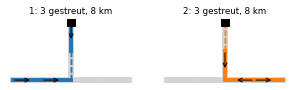

In [ ]:
netz = NETZ['hinweise_abb3']
print('gierig:')
zeige(netz, fahrten(netz, gieriger_plan(netz)))
print('gierige Reihenfolge, beste Aufteilung:', laenge(netz, folge_aus(gieriger_plan(netz))), 'km')
folge_abb3, km_abb3, verlauf_abb3 = suche(netz, 2)
print('iterierte lokale Suche mit 2 Runden, Verlauf:', verlauf_abb3)
zeige(netz, fahrten(netz, bester_plan(netz, folge_abb3)[1]))
zeichne(netz, fahrten(netz, bester_plan(netz, folge_abb3)[1]))

## Alle Beispiele

Für jedes Netz: der einfache Plan aus Teil 1, das gierige Verfahren, die lokale Suche ab der gierigen Folge und die iterierte lokale
Suche (bei den beiden Beispielen aus dem Aufgabenblatt das Ergebnis von oben mit einer Runde, sonst mit 6 Runden), bei bis zu
10 Abschnitten außerdem der exakte Wert. Jeder Plan ist mit `pruefe` nachgerechnet.

In [ ]:
BESTER = {}
print(f"{'Netz':22} {'m':>3} {'T':>3} {'einfach':>8} {'gierig':>7} {'lokal':>6} {'iteriert':>9} {'exakt':>6}")
for name, netz in NETZ.items():
    einfach = pruefe(netz, fahrten(netz, einfacher_plan(netz)))
    gierig = pruefe(netz, fahrten(netz, gieriger_plan(netz)))
    if name not in LOKAL:
        LOKAL[name] = verbessere(netz, folge_aus(gieriger_plan(netz)))[1]
    if name not in ERGEBNIS:
        ERGEBNIS[name] = suche(netz, 6)[0]
    km, plan = bester_plan(netz, ERGEBNIS[name])
    BESTER[name] = pruefe(netz, fahrten(netz, plan))
    genau = '-'
    if len(netz['abschnitte']) <= 10:
        genau = pruefe(netz, exakt(netz)[0])
    print(f"{name:22} {len(netz['abschnitte']):3} {netz['T']:3} {einfach:8} {gierig:7} {LOKAL[name]:6} {BESTER[name]:9} {genau:>6}")

Netz                     m   T  einfach  gierig  lokal  iteriert  exakt
beispiel1               33  12      148      60     60        60      -
beispiel2               44  12      208      90     82        80      -
hinweise_abb1           10   4       32      24     18        18     18
hinweise_abb3            6   3       22      18     18        16     16
sackgasse                7   3       32      32     24        24     24
gitter                  24   8       72      38     38        34      -
beispiel1_depot_mitte   33  12      136      48     48        42      -


Die iterierte lokale Suche erreicht bei beiden Beispielen aus dem Aufgabenblatt die Werte der Lösungshinweise (60 km und 80 km) und
bei den kleinen Netzen das Optimum. Beim Gitter und bei Beispiel 1 mit dem Depot in der Mitte bringen die Runden mit Störungen noch
viel (38 → 34 km und 48 → 42 km).

Bei Beispiel 2 reicht mit der Startzahl 1 schon eine Runde. Das ist auch Glück: In Versuchen außerhalb des Notebooks mit den
Startzahlen 1 bis 5 und je 10 Runden erreichte die Suche die 80 km nach 1, 6, 6 und 2 Runden; mit Startzahl 5 blieb sie bei 82 km.
Wer sicher gehen will, lässt die Suche mit mehreren Startzahlen laufen und nimmt das beste Ergebnis.

Die Pläne für die beiden Beispiele:

beispiel1
Rundfahrt 1: 12 km gestreut, 24 km gefahren
    (0|0) --> (3|0) --> (3|3) ==> (3|6) ==> (6|6) ==> (6|3) --> (6|0) ==> (3|0) --> (0|0)
Rundfahrt 2: 12 km gestreut, 18 km gefahren
    (0|0) --> (6|0) ==> (6|3) ==> (3|3) ==> (3|0) ==> (0|0)
Rundfahrt 3:  9 km gestreut, 18 km gefahren
    (0|0) ==> (0|1) --> (0|4) ==> (0|6) ==> (3|6) --> (0|6) --> (0|4) ==> (0|1) --> (0|0)
Gesamtstrecke: 60 km

beispiel2
Rundfahrt 1: 12 km gestreut, 20 km gefahren
    (0|0) ==> (0|1) --> (0|3) ==> (0|6) ==> (4|6) ==> (4|5) ==> (3|5) --> (2|5) ==> (1|5)
    ==> (1|4) --> (0|4) --> (0|0)
Rundfahrt 2: 10 km gestreut, 14 km gefahren
    (0|0) --> (0|1) ==> (0|2) --> (0|4) ==> (1|4) ==> (1|1) ==> (3|1) ==> (3|0) ==> (1|0)
    --> (0|0)
Rundfahrt 3: 10 km gestreut, 22 km gefahren
    (0|0) ==> (1|0) --> (3|0) ==> (6|0) ==> (6|4) --> (5|4) ==> (5|5) ==> (4|5) --> (1|5)
    --> (1|4) --> (0|4) --> (0|0)
Rundfahrt 4: 12 km gestreut, 24 km gefahren
    (0|0) --> (3|0) --> (3|1) ==> (5|1) ==> (5|4) ==> (6|4

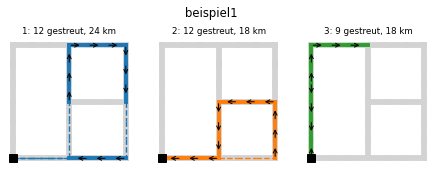

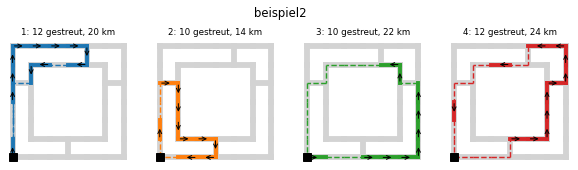

In [ ]:
for name in ['beispiel1', 'beispiel2']:
    netz = NETZ[name]
    km, plan = bester_plan(netz, ERGEBNIS[name])
    print(name)
    zeige(netz, fahrten(netz, plan))
    zeichne(netz, fahrten(netz, plan), name)
    print()

Unsere Pläne sind genauso lang wie die der Lösungshinweise (Abbildung 6 dort), sehen aber anders aus; es gibt mehrere kürzeste
Pläne. Bei Beispiel 1 streuen die drei Rundfahrten wie in den Hinweisen 12, 12 und 9 km. Manche Abschnitte fährt Konrad zuerst
ohne zu streuen und streut sie erst auf dem Rückweg, z. B. in Rundfahrt 3 von Beispiel 1 das Stück von (0|1) bis (0|4). Das
kostet nichts extra.

Die eigenen Netze:

sackgasse
Rundfahrt 1:  1 km gestreut,  2 km gefahren
    (0|0) ==> (1|0) --> (0|0)
Rundfahrt 2:  3 km gestreut, 14 km gefahren
    (0|0) --> (5|0) ==> (7|0) --> (5|0) ==> (4|0) --> (0|0)
Rundfahrt 3:  3 km gestreut,  8 km gefahren
    (0|0) --> (1|0) ==> (4|0) --> (0|0)
Gesamtstrecke: 24 km

gitter
Rundfahrt 1:  8 km gestreut, 14 km gefahren
    (0|0) --> (0|2) ==> (2|2) --> (1|2) --> (1|3) ==> (3|3) ==> (3|0) ==> (2|0) --> (0|0)
Rundfahrt 2:  8 km gestreut, 12 km gefahren
    (0|0) --> (1|0) ==> (2|0) ==> (2|1) ==> (3|1) --> (3|2) ==> (2|2) ==> (2|3) --> (2|2)
    ==> (2|1) ==> (0|1) --> (0|0)
Rundfahrt 3:  8 km gestreut,  8 km gefahren
    (0|0) ==> (1|0) ==> (1|3) ==> (0|3) ==> (0|0)
Gesamtstrecke: 34 km

beispiel1_depot_mitte
Rundfahrt 1: 12 km gestreut, 12 km gefahren
    (3|3) ==> (6|3) ==> (6|0) ==> (3|0) ==> (3|3)
Rundfahrt 2:  9 km gestreut, 12 km gefahren
    (3|3) ==> (3|6) ==> (6|6) ==> (6|3) --> (3|3)
Rundfahrt 3: 12 km gestreut, 18 km gefahren
    (3|3) --> (3|0) ==> (0|

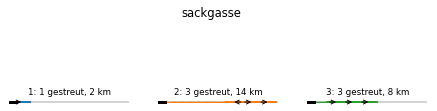

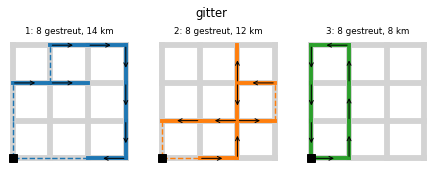

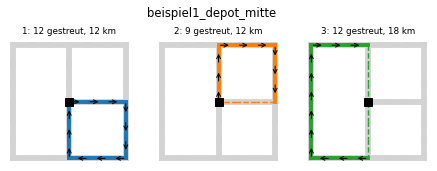

In [ ]:
for name in ['sackgasse', 'gitter', 'beispiel1_depot_mitte']:
    netz = NETZ[name]
    km, plan = bester_plan(netz, ERGEBNIS[name])
    print(name)
    zeige(netz, fahrten(netz, plan))
    zeichne(netz, fahrten(netz, plan), name)
    print()

In der Sackgasse findet die Suche wieder 24 km wie die exakte Rechnung, nur mit den Rundfahrten in anderer Reihenfolge (die spielt
keine Rolle). Beim Gitter sind es 34 km. Bei Beispiel 1 mit dem Depot in der Mitte kommt die Suche auf 42 km, und das ist sicher
optimal: Hängt man alle Rundfahrten am Depot hintereinander, bekommt man eine einzige Rundfahrt über alle Straßen, und die ist
mindestens so lang wie die kürzeste Rundfahrt beim Briefträgerproblem (42 km, siehe Teil 4).

## Teil 4: Welchen Einfluss hat die Ladekapazität?

**T = 1.** Jeder Abschnitt braucht eine eigene Rundfahrt: vom Depot zum einen Ende, über den Abschnitt und vom anderen Ende
zurück. Die Reihenfolge spielt keine Rolle. Ein Abschnitt von u nach v kostet also abstand(Depot, u) + 1 + abstand(v, Depot), und
die Gesamtstrecke ist die Summe darüber. Das ist leicht zu berechnen.

**T ≥ m.** Der Sand reicht für alles, Konrad braucht nur eine Rundfahrt über alle Straßen. Das ist das **Briefträgerproblem**
(Chinese Postman Problem), und dafür gibt es ein schnelles Verfahren: Eine Rundfahrt, die jeden Abschnitt genau einmal benutzt
(eine **Eulertour**), gibt es genau dann, wenn an jedem Punkt eine gerade Anzahl von Abschnitten zusammenkommt. An den Punkten
mit ungerader Anzahl muss Konrad Abschnitte doppelt fahren. Diese Punkte fasst man so zu Paaren zusammen, dass die Summe der
Abstände der Paare möglichst klein ist, und fährt die Wege zwischen den Paaren doppelt. Wir probieren alle Paarungen durch (bei 8
ungeraden Punkten sind das 7 · 5 · 3 · 1 = 105); für viele Punkte gibt es ein schnelles Matching-Verfahren (Edmonds).

**Dazwischen.** Für die Kapazitäten zwischen 1 und m heißt das Problem *Capacitated Arc Routing Problem* (CARP) und ist NP-schwer:
Niemand kennt ein Verfahren, das immer schnell den kürzesten Plan findet. Bei unserem Verfahren hängt der Aufwand für eine
Bewertung von T ab: höchstens m · T Schritte. Die Lösungshinweise haben gemessen, dass ihre Rechenzeit ungefähr linear mit T wächst.

In [ ]:
def nur_einzeln(netz):
    """Gesamtstrecke für T = 1."""
    vom_depot = netz['abstand'][netz['depot']]
    return sum(vom_depot[a] + 1 + vom_depot[b] for a, b in netz['abschnitte'])


def paarung(netz, punkte):
    """Kleinste Summe der Abstände, wenn man die Punkte zu Paaren zusammenfasst (alle Paarungen, rekursiv)."""
    if len(punkte) == 0:
        return 0
    erster = punkte[0]
    bester = UNENDLICH
    for k in range(1, len(punkte)):
        rest = punkte[1:k] + punkte[k + 1:]
        bester = min(bester, netz['abstand'][erster][punkte[k]] + paarung(netz, rest))
    return bester


def brieftraeger(netz):
    """Gesamtstrecke für T >= m: alle Abschnitte plus die doppelt gefahrenen Wege zwischen ungeraden Punkten."""
    ungerade = [p for p in netz['nachbarn'] if len(netz['nachbarn'][p]) % 2 == 1]
    return len(netz['abschnitte']) + paarung(netz, ungerade)


for name in ['beispiel1', 'beispiel2']:
    netz = NETZ[name]
    print(f'{name}: T = 1 -> {nur_einzeln(netz)} km,   T >= {len(netz["abschnitte"])} -> {brieftraeger(netz)} km')

beispiel1: T = 1 -> 438 km,   T >= 33 -> 42 km
beispiel2: T = 1 -> 602 km,   T >= 44 -> 48 km


Jetzt lassen wir unsere Suche für Beispiel 1 mit verschiedenen Kapazitäten laufen. `dict(netz, T=T)` ist eine Kopie des Netzes mit
anderem T. „Schritte je Bewertung“ zählt, wie oft die innere Schleife von `aufteilung` höchstens läuft.

In [ ]:
netz = NETZ['beispiel1']
m = len(netz['abschnitte'])
KAPAZITAET = {}
print(f"{'T':>3} {'Strecke':>8} {'Rundfahrten':>12} {'Bewertungen':>12} {'Schritte je Bewertung':>22}  Vergleich")
for T in [1, 2, 3, 4, 6, 8, 12, 16, 24, 33]:
    netz_T = dict(netz, T=T)
    zaehler['bewertungen'] = 0
    folge, km, verlauf = suche(netz_T, 0)
    bewertungen = zaehler['bewertungen']
    km, plan = bester_plan(netz_T, folge)
    KAPAZITAET[T] = pruefe(netz_T, fahrten(netz_T, plan))
    schritte = sum(min(T, m - j) for j in range(m))
    vergleich = ''
    if T == 1:
        vergleich = f'Formel: {nur_einzeln(netz_T)}'
    if T >= m:
        vergleich = f'Briefträger: {brieftraeger(netz_T)}'
    print(f'{T:3} {KAPAZITAET[T]:8} {len(plan):12} {bewertungen:12} {schritte:22}  {vergleich}')

  T  Strecke  Rundfahrten  Bewertungen  Schritte je Bewertung  Vergleich
  1      438           33         1585                     33  Formel: 438
  2      242           17         3169                     65  
  3      168           11         1585                     96  
  4      136            9         3169                    126  
  6      102            6         3169                    183  
  8       78            5         3169                    236  
 12       60            3         1585                    330  
 16       50            3         1585                    408  
 24       48            2         1585                    516  
 33       42            1         4753                    561  Briefträger: 42


Bei T = 1 und T = 33 trifft die Suche die genauen Werte (Formel und Briefträgerproblem). Für die Werte dazwischen kennen wir das
Optimum nicht. Damit die Zelle nicht zu lange rechnet, lief hier nur die lokale Suche ohne Störungen (`suche(netz_T, 0)`). Außerhalb
des Notebooks hat die iterierte Suche mit 8 Runden bei T = 2, 4 und 6 noch kürzere Pläne gefunden (234, 134 und 96 km statt 242,
136 und 102 km); bei T = 3, 8, 16 und 24 blieb es bei den Werten der Tabelle.

Die Schritte je Bewertung wachsen mit T, für kleine T ungefähr linear (für jedes j sind es min(T, m − j)). Das passt zu den
Lösungshinweisen, die eine ungefähr linear mit T wachsende Rechenzeit gemessen haben. Die Zahl der Bewertungen hängt dagegen kaum von T ab.

Zum Vergleich die exakte Suche für das kleine Netz aus Abbildung 1a mit allen Kapazitäten von 1 bis m = 10:

In [ ]:
netz = NETZ['hinweise_abb1']
EXAKT_ABB1 = {}
SUCHE_ABB1 = {}
print(f"{'T':>3} {'exakt':>6} {'Zustände':>9} {'Suche, 2 Runden':>16} {'Suche, 10 Runden':>17}")
for T in range(1, 11):
    netz_T = dict(netz, T=T)
    alle_fahrten, zustaende = exakt(netz_T)
    EXAKT_ABB1[T] = pruefe(netz_T, alle_fahrten)
    SUCHE_ABB1[T] = (suche(netz_T, 2)[1], suche(netz_T, 10)[1])
    print(f'{T:3} {EXAKT_ABB1[T]:6} {zustaende:9} {SUCHE_ABB1[T][0]:16} {SUCHE_ABB1[T][1]:17}')

  T  exakt  Zustände  Suche, 2 Runden  Suche, 10 Runden
  1     50     17386               50                50
  2     28     25444               28                28
  3     22     33133               22                22
  4     18     39545               18                18
  5     16     43824               16                16
  6     16     46675               16                16
  7     16     47801               16                16
  8     14     47896               16                14
  9     14     46135               16                14
 10     12     40298               12                12


Die Zahl der erreichten Zustände steigt von 17 386 bei T = 1 auf fast 48 000 bei T = 8 (es gibt mehr verschiedene Sandmengen) und
fällt dann wieder etwas, weil die Breitensuche früher am Ziel ist. Für die exakte Suche ist die Ladekapazität also nicht das
Entscheidende, sondern die 2^m Teilmengen der Abschnitte. Bei T = 10 kommen 12 km heraus, genau der Wert des Briefträgerproblems.
Unsere Suche findet mit 2 Runden bei T = 8 und T = 9 nur 16 km statt 14 km, mit 10 Runden überall das Optimum.

## Für Neugierige

### Wie oft trifft die Suche das Optimum?

Wir erzeugen zufällige kleine Netze: Ausgehend von einem zufälligen Punkt auf einem Raster von 4 × 3 km hängen wir so lange
zufällige Abschnitte an, bis das Netz 8 bis 10 Abschnitte hat. Depot und Kapazität (2 bis 4) wählen wir auch zufällig. Dann
vergleichen wir die iterierte lokale Suche (mit 2 und mit 10 Runden) mit der exakten Breitensuche.

In [ ]:
def zufallsnetz(zufall):
    anzahl = zufall.randint(8, 10)
    punkte = {(zufall.randint(0, 4), zufall.randint(0, 3))}
    abschnitte = set()
    while len(abschnitte) < anzahl:
        x, y = zufall.choice(sorted(punkte))
        dx, dy = zufall.choice([(1, 0), (-1, 0), (0, 1), (0, -1)])
        q = (x + dx, y + dy)
        if 0 <= q[0] <= 4 and 0 <= q[1] <= 3:
            abschnitte.add((min((x, y), q), max((x, y), q)))
            punkte.add(q)
    return baue_netz(zufall.randint(2, 4), zufall.choice(sorted(punkte)), sorted(abschnitte))


zufall = random.Random(2012)
VERGLEICH = []
for nr in range(20):
    netz = zufallsnetz(zufall)
    genau = pruefe(netz, exakt(netz)[0])
    ergebnis = [genau]
    for runden in [2, 10]:
        folge, km, verlauf = suche(netz, runden, startzahl=nr)
        ergebnis.append(pruefe(netz, fahrten(netz, bester_plan(netz, folge)[1])))
    VERGLEICH.append(ergebnis)
for k, runden in [(1, 2), (2, 10)]:
    gleich = sum(1 for ergebnis in VERGLEICH if ergebnis[k] == ergebnis[0])
    print(f'Suche mit {runden:2} Runden: {gleich} von {len(VERGLEICH)} Netzen optimal')
for nr in range(len(VERGLEICH)):
    if VERGLEICH[nr][1] != VERGLEICH[nr][0] or VERGLEICH[nr][2] != VERGLEICH[nr][0]:
        print(f'  Netz {nr}: Optimum {VERGLEICH[nr][0]} km, mit 2 Runden {VERGLEICH[nr][1]} km, mit 10 Runden {VERGLEICH[nr][2]} km')

Suche mit  2 Runden: 19 von 20 Netzen optimal
Suche mit 10 Runden: 20 von 20 Netzen optimal
  Netz 7: Optimum 26 km, mit 2 Runden 28 km, mit 10 Runden 26 km


Mit 2 Runden trifft die Suche bei 19 von 20 Netzen das Optimum, mit 10 Runden bei allen. Das zeigt natürlich nicht, dass sie bei
großen Netzen immer den kürzesten Plan findet; bei NP-schweren Problemen muss man damit leben.

### Weitere Ideen aus den Lösungshinweisen

- **Schleifenfahrten:** Fahrten, die in eine Straße hineinfahren, ein Stück streuen und wieder umkehren (wie in der Sackgasse). Mit
  unserer Darstellung (Abschnitte von 1 km) sind sie von selbst möglich. Wer längere Straßenstücke als Ganzes betrachtet
  (segmentbasierte Darstellung der Hinweise), muss sie ausdrücklich erlauben, sonst schließt er optimale Pläne aus.
- **Bessere Startfolgen und weitere Änderungen:** Die Hinweise nennen klüger gewählte zufällige Startreihenfolgen. Wir beginnen mit
  der gierigen Folge und stören sie zufällig.
- **Erweiterungen:** Streuen nicht jederzeit an- und ausschalten können, Straßen mit höherem Streubedarf, mehrere Streuwagen
  gleichzeitig (dann soll die längste Rundfahrt möglichst kurz sein).

## Zum Schluss: Der kürzeste Plan mit MiniZinc

MiniZinc kann bei kleinen Netzen den kürzesten Plan finden und beweisen, dass es keinen kürzeren gibt. Bei den Beispielen aus dem
Aufgabenblatt wollen wir wissen, ob 60 km und 80 km wirklich optimal sind (die Lösungshinweise sagen es, beweisen es aber nicht).

**Das Modell.** Jeder Abschnitt gibt zwei **Bögen**, einen für jede Richtung. Für jede der höchstens K Rundfahrten `r` und jeden
Bogen `a` gibt es drei Variablen:
- `x[r, a]`: wie oft die Rundfahrt über den Bogen fährt (0 bis 2; öfter lohnt sich nie),
- `s[r, a]`: 1, wenn sie dabei den Abschnitt streut,
- `f[r, a]`: ein „Fluss“, der dafür sorgt, dass die Rundfahrt am Depot hängt.

Die Bedingungen: Jeder Abschnitt wird genau einmal gestreut, jede Rundfahrt streut höchstens T Abschnitte, und an jedem Punkt fährt
sie so oft hinein wie heraus. Das allein reicht aber nicht: Dann könnte eine „Rundfahrt“ auch aus einem Kreis irgendwo in der Stadt
bestehen, der gar nicht am Depot vorbeikommt. Deshalb schickt das Depot für jede Rundfahrt so viele Einheiten Fluss los, wie sie
Abschnitte streut, und jeder gestreute Abschnitt verbraucht eine Einheit an seinem Anfang. Fluss darf nur über Bögen laufen, über die
die Rundfahrt fährt (`f[r, a] <= T * x[r, a]`). So muss jeder gestreute Abschnitt vom Depot aus erreichbar sein. Die Rundfahrten
sortieren wir nach der gestreuten Menge, damit der Solver nicht dieselbe Lösung in allen Reihenfolgen der Rundfahrten durchsucht.

Neu gegenüber den Arbeitsblättern sind der Operator `++`, der zwei Arrays hintereinanderhängt, und `if … then … else … endif`
innerhalb einer Summe (nur beim Depot kommt der Fluss dazu).

**Wie viele Rundfahrten?** Zwei Rundfahrten, die zusammen höchstens T Abschnitte streuen, kann man zu einer zusammenlegen (erst die
eine, dann ohne Halt im Depot die andere), ohne dass der Plan länger wird. Es gibt also einen kürzesten Plan, in dem höchstens eine
Rundfahrt T/2 oder weniger Abschnitte streut. Damit reicht K = (m − 1) // (T // 2 + 1) + 1.

```minizinc
% Ned: Streuplan als CARP (Capacitated Arc Routing Problem)
int: n;                           % Punkte 1..n
int: m;                           % Abschnitte 1..m
int: depot;
int: T;                           % Ladekapazität
int: K;                           % höchstens so viele Rundfahrten
array[1..m] of 1..n: von;
array[1..m] of 1..n: nach;

% Jeder Abschnitt gibt zwei Bögen: e von -> nach und e + m nach -> von
set of int: BOEGEN = 1..2 * m;
array[BOEGEN] of 1..n: start = von ++ nach;
array[BOEGEN] of 1..n: ziel = nach ++ von;

array[1..K, BOEGEN] of var 0..2: x;   % wie oft Rundfahrt r über Bogen a fährt
array[1..K, BOEGEN] of var 0..1: s;   % 1, wenn Rundfahrt r den Abschnitt auf Bogen a streut
array[1..K, BOEGEN] of var 0..T: f;   % Fluss: so viele Abschnitte streut r noch hinter Bogen a

% jeder Abschnitt wird genau einmal gestreut, beim Streuen fährt man auch darüber
constraint forall(e in 1..m)(sum(r in 1..K)(s[r, e] + s[r, e + m]) = 1);
constraint forall(r in 1..K, a in BOEGEN)(s[r, a] <= x[r, a]);
% Ladekapazität; Rundfahrten nach der gestreuten Menge sortiert (gegen Symmetrie)
constraint forall(r in 1..K)(sum(a in BOEGEN)(s[r, a]) <= T);
constraint forall(r in 1..K - 1)(sum(a in BOEGEN)(s[r, a]) >= sum(a in BOEGEN)(s[r + 1, a]));
% an jedem Punkt fährt jede Rundfahrt so oft hinein wie heraus
constraint forall(r in 1..K, k in 1..n)(
  sum(a in BOEGEN where ziel[a] = k)(x[r, a]) = sum(a in BOEGEN where start[a] = k)(x[r, a]));
% Zusammenhang mit dem Depot: Das Depot schickt so viele Einheiten los, wie r streut; jeder gestreute Bogen
% verbraucht eine Einheit an seinem Anfang. Fluss gibt es nur auf Bögen, über die r fährt.
constraint forall(r in 1..K, a in BOEGEN)(f[r, a] <= T * x[r, a]);
constraint forall(r in 1..K, k in 1..n)(
  sum(a in BOEGEN where ziel[a] = k)(f[r, a]) - sum(a in BOEGEN where start[a] = k)(f[r, a])
  + (if k = depot then sum(a in BOEGEN)(s[r, a]) else 0 endif)
  = sum(a in BOEGEN where start[a] = k)(s[r, a]));

var int: gesamt = sum(r in 1..K, a in BOEGEN)(x[r, a]);
solve minimize gesamt;

output ["gesamt = \(gesamt)\n"] ++
       ["Rundfahrt \(r): \(sum(a in BOEGEN)(s[r, a])) gestreut, \(sum(a in BOEGEN)(x[r, a])) km\n" | r in 1..K];
```

Die Datendatei schreibt `als_dzn`; die Punkte werden dafür durchnummeriert.

In [ ]:
def als_dzn(netz, K=None):
    punkte = sorted(netz['nachbarn'])
    nummer = {}
    for i in range(len(punkte)):
        nummer[punkte[i]] = i + 1
    m = len(netz['abschnitte'])
    if K is None:
        K = (m - 1) // (netz['T'] // 2 + 1) + 1        # so viele Rundfahrten reichen immer
    von = [nummer[a] for a, b in netz['abschnitte']]
    nach = [nummer[b] for a, b in netz['abschnitte']]
    return (f"n = {len(punkte)};\nm = {m};\ndepot = {nummer[netz['depot']]};\nT = {netz['T']};\nK = {K};\n"
            f"von = {von};\nnach = {nach};")


print(als_dzn(NETZ['hinweise_abb3']))

n = 7;
m = 6;
depot = 5;
T = 3;
K = 3;
von = [1, 2, 3, 3, 4, 6];
nach = [2, 3, 4, 6, 5, 7];


Mit dem Solver HiGHS:

`hinweise_abb3`:

**Ausgabe:**

```
gesamt = 16
Rundfahrt 1: 3 gestreut, 8 km
Rundfahrt 2: 3 gestreut, 8 km
Rundfahrt 3: 0 gestreut, 0 km
----------
==========
```

`hinweise_abb1`:

**Ausgabe:**

```
gesamt = 18
Rundfahrt 1: 4 gestreut, 8 km
Rundfahrt 2: 4 gestreut, 6 km
Rundfahrt 3: 2 gestreut, 4 km
Rundfahrt 4: 0 gestreut, 0 km
----------
==========
```

`sackgasse`:

**Ausgabe:**

```
gesamt = 24
Rundfahrt 1: 3 gestreut, 14 km
Rundfahrt 2: 3 gestreut, 8 km
Rundfahrt 3: 1 gestreut, 2 km
Rundfahrt 4: 0 gestreut, 0 km
----------
==========
```

Rundfahrten mit 0 gestreuten Abschnitten fallen einfach weg; K ist nur eine Obergrenze.

Bei den kleinen Netzen ist HiGHS nach wenigen Sekunden fertig und bestätigt die Werte der exakten Breitensuche (16, 18 und
24 km); `==========` heißt, dass der Solver bewiesen hat, dass es nicht kürzer geht. CP-SAT ist hier ähnlich schnell, Chuffed und
Gecode brauchten beim Netz aus Abbildung 1a dagegen länger als eine Minute.

Bei den beiden Beispielen aus dem Aufgabenblatt ist das Modell zu schwer. Außerhalb des Notebooks haben wir gemessen:
- HiGHS findet mit K = 3 bzw. K = 4 Rundfahrten (weniger geht nicht) in 5 Minuten Pläne mit 60 km und 80 km, kann aber nicht
  beweisen, dass es nicht kürzer geht. Bei Beispiel 1 lag die untere Schranke nach 2 Minuten erst bei 54 km.
- CP-SAT (mit 8 Threads, Option `-p 8`) beweist für Beispiel 1 mit K = 3 in etwa 1,5 Minuten: Mit drei Rundfahrten geht es nicht
  kürzer als 60 km. Mit K = 5 (so viele verlangt unsere Formel, erst dann gilt der Beweis für alle Pläne) und für Beispiel 2 mit
  K = 4 kam CP-SAT in 10 Minuten zu keinem Ergebnis und musste beendet werden.

Ganz sicher wissen wir also nicht, dass 60 km und 80 km optimal sind. Die Lösungshinweise nennen ihre Pläne „Streupläne mit
minimaler Gesamtfahrstrecke“, und auch unsere Suche hat in keinem Versuch kürzere gefunden. Das ist typisch für NP-schwere
Probleme: Gute Lösungen zu finden ist oft leicht, zu beweisen, dass es keine besseren gibt, ist schwer.